---

## **Curso**: Residência em Inteligência Artificial  
## **Unidade Curricular**: Visão Computacional  
## **Professor**: Matheus Vanzan
## **Alunos**: Ana Carolina Dutra, Camila Gois de Jesus e Guilherme Magalhães Junior
## Desafio Semana 3
---

## Sistema de Recomendação por Similaridade usando CNN Pré-Treinada



### 1. Contexto

Sistemas de recomendação baseados em **similaridade visual** aparecem em grandes plataformas como Amazon, Shopee e Mercado Livre.  
A ideia é simples: dado um produto, encontrar outros produtos **visualmente parecidos**.

Neste desafio, você irá criar um protótipo desse sistema usando **Feature Extraction** com uma CNN pré-treinada.

### 2. Objetivo Geral

Desenvolver um sistema capaz de:

- Carregar um dataset de produtos.
- Extrair **vetores de características** (embeddings) usando Transfer Learning.
- Calcular similaridade entre produtos.
- Recomendar os itens mais parecidos.
- Buscar itens semelhantes a uma **imagem externa** enviada por você.

### 3. Dataset

Use qualquer dataset de produtos, por exemplo:

- *Retail Products Dataset* (Kaggle)  
- *Fashion Product Images*  
- *Shopee Matching* (subset)  
- Ou outro dataset que contenha imagens de produtos

Se preferir, selecione apenas um subconjunto.


### 4. Atividades Obrigatórias

#### **4.1. Preparação dos dados**
- Carregue e organize as imagens.
- Redimensione para o shape necessário (ex.: 224×224).
- Separe treino/validação se necessário.

#### **4.2. Extração de Features com CNN Pré-Treinada**
- Utilize EfficientNetB0 (ou outra da sua escolha).
- Remova a camada final de classificação.
- Gere um vetor de características para cada imagem.

Dica: use `GlobalAveragePooling2D` como saída.

#### **4.3. Construir o Índice de Similaridade**
- Armazene todos os vetores de features em um array NumPy.
- Implemente uma função de distância (cosine ou euclidiana).
- Crie uma função:

```python
def recomendar(img, k=5):
    # retorna as k imagens mais parecidas
````

#### **4.4. Recomendação de Produtos**

* Escolha uma imagem do dataset como consulta.
* Mostre:

  * A imagem de entrada
  * As 5 imagens mais parecidas

#### **4.5. Busca por Imagem Externa**

* Faça upload de uma imagem (de fora do dataset).
* Extraia suas features.
* Busque no dataset as imagens mais similares.
* Mostre o resultado graficamente.

### 5. Entrega

Seu notebook deve conter:

1. Preparação do dataset
2. Construção do extrator de features
3. Extração dos vetores
4. Implementação da função de recomendação
5. Testes com:

   * imagem do dataset
   * imagem externa
6. Visualização das recomendações
7. Pequena análise final:

   * A similaridade fez sentido?
   * O que você melhoraria?

#Início da atividade

##Importação do datset

Dentre alguns datasets de e-commerce disponiveis do Kaggle, decidimos pelo "Mini Fashion Product Images and Text Dataset", que é uma versão "limpa" e diminuta do dataset "Fashion Product Images Dataset" pela quantidade de imagens(44.4k) e tamanho reduzido(496.44 MB).

Logo na descrição do dataset, já tem uma explicação sobre o tamanho das imagens: 256 X 256 px. Tamanho que manteremos para o exercício.

In [1]:
import kagglehub
import os
import pandas as pd
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing import image

path = kagglehub.dataset_download("nirmalsankalana/mini-product-image-and-text-dataset")
print("Caminho do Dataset:", path)


100%|██████████| 345M/345M [00:03<00:00, 101MB/s]

Extracting files...


Caminho do Dataset: /root/.cache/kagglehub/datasets/nirmalsankalana/mini-product-image-and-text-dataset/versions/1


In [2]:
# Carrega o CSV com os nomes das imagens e categorias
df_catalogo = pd.read_csv(os.path.join(path, 'data.csv'))
print(f"Total de produtos para o sistema de recomendação: {len(df_catalogo)}")

Total de produtos para o sistema de recomendação: 44441


##Extração das Features

Found 44441 files.


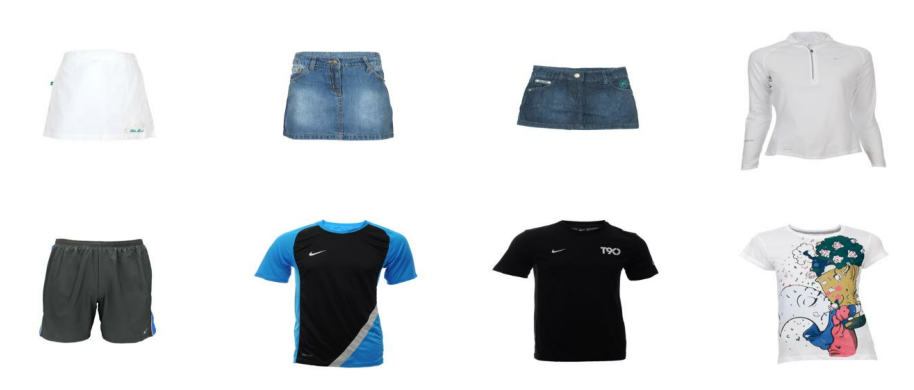

In [3]:
ds_vdd = tf.keras.preprocessing.image_dataset_from_directory(
    path,
    labels=None,
    image_size=(256, 256),
    interpolation="bilinear",
    batch_size=32,
    # A ordem precisa permanecer fixa para que cada embedding corresponda
    # ao mesmo arquivo usado posteriormente na visualização.
    shuffle=False,
)

# Guarde os caminhos antes de map/prefetch, pois esses objetos transformados
# não preservam o atributo file_paths.
caminhos_tf = tuple(ds_vdd.file_paths)


plt.figure(figsize=(10, 4))

for imgs in ds_vdd.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import tensorflow as tf

# 1. Ajustamos a função para aceitar apenas a imagem como argumento
def converter_para_grayscale(imagem):
    # Converte de RGB para escala de cinza (1 canal)
    cinza = tf.image.rgb_to_grayscale(imagem)

    # Replica o canal 3 vezes para manter o formato compatível (H, W, 3)
    cinza_3_canais = tf.image.grayscale_to_rgb(cinza)

    return cinza_3_canais

print("Criando a cópia em escala de cinza...")

# 2. Aplicamos o mapeamento (o TF agora passa apenas a imagem para a função)
ds = ds_vdd.map(
    converter_para_grayscale,
    num_parallel_calls=tf.data.AUTOTUNE,
    deterministic=True,
)

# Garante a paginação e performance na memória
ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)

print("✓ Cópia 'ds_grayscale' criada com sucesso e sem erros!")

Criando a cópia em escala de cinza...
✓ Cópia 'ds_grayscale' criada com sucesso e sem erros!


In [5]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_res

ResModel = tf.keras.applications.ResNet50

Res_model = ResModel(
    include_top=False,
    weights='imagenet',
    input_shape=(256,  256, 3)
)

Res_model.trainable = False
Res_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [6]:
#PRA RES
inputs = tf.keras.Input(shape=(256, 256, 3))
x = Res_model(inputs, training=False)
outputs = tf.keras.layers.GlobalAveragePooling2D()(x)
model_extractor_res = tf.keras.Model(inputs, outputs)

def extrair_embeddings(dataset, modelo, preprocessador_especifico):
    features_list = []

    for images in dataset:
        # Agora a função usa o preprocessador correto passado por argumento!
        images_prepped = preprocessador_especifico(images)
        features = modelo(images_prepped, training=False)
        features_list.append(features.numpy())

    features_finais = np.concatenate(features_list, axis=0)
    return features_finais

RES_embeddings = extrair_embeddings(ds, model_extractor_res, preprocess_res)

print('Formato final dos embeddings:', RES_embeddings.shape)

Formato final dos embeddings: (44441, 2048)


In [7]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_efficient
B0Model = tf.keras.applications.EfficientNetB0
B0_model = B0Model(
    include_top=False,
    weights='imagenet',
    input_shape=(256,  256, 3)
)

B0_model.trainable = False
B0_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 256, 256,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 256, 256,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
#EfficientNetB0
inputs = tf.keras.Input(shape=(256, 256, 3))
x = B0_model(inputs, training=False)
outputs = tf.keras.layers.GlobalAveragePooling2D()(x)
model_extractor_b0 = tf.keras.Model(inputs, outputs)


B0_embeddings = extrair_embeddings(ds, model_extractor_b0, preprocess_efficient)

print('Formato final dos embeddings:', B0_embeddings.shape)

Formato final dos embeddings: (44441, 1280)


In [9]:
#Mobile
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as preprocess_mobile

MB_model = MobileNetV2(
    include_top=False,
    weights='imagenet',
    input_shape=(256, 256, 3)
)
MB_model.trainable = False

inputs_mb = tf.keras.Input(shape=(256, 256, 3))
x_mb = MB_model(inputs_mb, training=False)
outputs_mb = tf.keras.layers.GlobalAveragePooling2D()(x_mb)
model_extractor_mb = tf.keras.Model(inputs_mb, outputs_mb)

MB_embeddings = extrair_embeddings(ds, model_extractor_mb, preprocess_mobile)

print('Formato final dos embeddings MobileNetV2:', MB_embeddings.shape)

/tmp/ipykernel_1075/2350214825.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  MB_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Formato final dos embeddings MobileNetV2: (44441, 1280)


In [10]:
#vgg19
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input as preprocess_vgg

print("Iniciando extração com VGG19...")

VGG19_base = VGG19(
    include_top=False,
    weights='imagenet',
    input_shape=(256, 256, 3)
)
VGG19_base.trainable = False

inputs_vgg = tf.keras.Input(shape=(256, 256, 3))
x_vgg = VGG19_base(inputs_vgg, training=False)
outputs_vgg = tf.keras.layers.GlobalAveragePooling2D()(x_vgg)
model_extractor_vgg = tf.keras.Model(inputs_vgg, outputs_vgg)


VGG_embeddings = extrair_embeddings(ds, model_extractor_vgg, preprocess_vgg)
print('Formato final dos embeddings VGG19:', VGG_embeddings.shape)


Iniciando extração com VGG19...
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Formato final dos embeddings VGG19: (44441, 512)


In [11]:
#inception
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inception

print("Iniciando extração com InceptionV3...")


Inception_base = InceptionV3(
    include_top=False,
    weights='imagenet',
    input_shape=(256, 256, 3)
)
Inception_base.trainable = False

inputs_inc = tf.keras.Input(shape=(256, 256, 3))
x_inc = Inception_base(inputs_inc, training=False)
outputs_inc = tf.keras.layers.GlobalAveragePooling2D()(x_inc)
model_extractor_inc = tf.keras.Model(inputs_inc, outputs_inc)

INC_embeddings = extrair_embeddings(ds, model_extractor_inc, preprocess_inception)
print('Formato final dos embeddings InceptionV3:', INC_embeddings.shape)

Iniciando extração com InceptionV3...
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Formato final dos embeddings InceptionV3: (44441, 2048)


## Contrução dos indices

Vamos comparar as distâncias cosseno, euclidiana e de correlação para cinco
modelos. O KNN usa a posição de cada vetor para localizar a imagem de origem.

Por padrão:

1. cosine (Similaridade Cosseno)
O ângulo entre os vetores no espaço, ignorando o tamanho deles


2. euclidean (Distância Euclidiana)

Distância em linha reta entre dois pontos


3. correlation (Distância de Correlação)
O quanto os padrões dos vetores sobem e descem juntos (estatisticamente).


In [12]:
# Os índices do KNN apontam diretamente para caminhos_tf, na ordem da extração.
for nome, embeddings in (
    ('ResNet50', RES_embeddings),
    ('EfficientNetB0', B0_embeddings),
    ('MobileNetV2', MB_embeddings),
    ('VGG19', VGG_embeddings),
    ('InceptionV3', INC_embeddings),
):
    if len(embeddings) != len(caminhos_tf):
        raise RuntimeError(
            f'{nome}: {len(embeddings)} embeddings para {len(caminhos_tf)} imagens. '
            'Execute novamente as células de carregamento e extração em ordem.'
        )

print(f"Índice de imagens disponível para {len(caminhos_tf)} embeddings por modelo.")

Índice de imagens disponível para 44441 embeddings por modelo.


In [13]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

def testar(id_produto, modelo_escolhido='resnet', metrica_escolhida='cosine', k=5):

    modelo = modelo_escolhido.lower()

    if modelo == 'resnet':
        embeddings_atendidos = RES_embeddings
    elif modelo in ['efficientnet', 'efficientnetb0', 'b0']:
        embeddings_atendidos = B0_embeddings
    elif modelo in ['mobilenet', 'mobilenetv2']:
        embeddings_atendidos = MB_embeddings
    elif modelo in ['vgg19', 'vgg']:
        embeddings_atendidos = VGG_embeddings
    elif modelo in ['inception', 'inceptionv3']:
        embeddings_atendidos = INC_embeddings
    else:
        raise ValueError(
            f"Modelo '{modelo_escolhido}' inválido! "
            "Escolha entre: 'resnet', 'efficientnet', 'mobilenet', 'vgg19' ou 'inception'."
        )

    knn = NearestNeighbors(metric=metrica_escolhida, algorithm='brute')
    knn.fit(embeddings_atendidos)

    vetor_foco = embeddings_atendidos[id_produto].reshape(1, -1)
    distancias, indices = knn.kneighbors(vetor_foco, n_neighbors=k + 1)

    # Exclui a própria consulta mesmo quando há empate na distância.
    outros_produtos = indices[0] != id_produto
    return indices[0][outros_produtos][:k], distancias[0][outros_produtos][:k]

In [14]:
# Lista de variações para o loop
modelos = ['resnet', 'efficientnet', 'mobilenet', 'vgg19', 'inception']
metricas = ['cosine', 'euclidean', 'correlation']

id_produto_teste = 1  # posição na ordem de caminhos_tf
k_vizinhos = 5

# Dicionário para guardar as variáveis com os resultados
experimentos = {}

print(f"Iniciando a bateria de testes para o produto ID {id_produto_teste}...\n")

# O loop que combina todo mundo
for modelo in modelos:
    for metrica in metricas:
        nome_experimento = f"{modelo}_{metrica}"

        indices, scores = testar(
            id_produto=id_produto_teste,
            modelo_escolhido=modelo,
            metrica_escolhida=metrica,
            k=k_vizinhos
        )

        # Guarda os resultados dentro do dicionário
        experimentos[nome_experimento] = {
            'caminho_consulta': caminhos_tf[id_produto_teste],
            'indices': indices,
            'scores': scores
        }

        print(f"-> Experimento [{nome_experimento.upper()}] concluído e salvo!")

Iniciando a bateria de testes para o produto ID 1...

-> Experimento [RESNET_COSINE] concluído e salvo!
-> Experimento [RESNET_EUCLIDEAN] concluído e salvo!
-> Experimento [RESNET_CORRELATION] concluído e salvo!
-> Experimento [EFFICIENTNET_COSINE] concluído e salvo!
-> Experimento [EFFICIENTNET_EUCLIDEAN] concluído e salvo!
-> Experimento [EFFICIENTNET_CORRELATION] concluído e salvo!
-> Experimento [MOBILENET_COSINE] concluído e salvo!
-> Experimento [MOBILENET_EUCLIDEAN] concluído e salvo!
-> Experimento [MOBILENET_CORRELATION] concluído e salvo!
-> Experimento [VGG19_COSINE] concluído e salvo!
-> Experimento [VGG19_EUCLIDEAN] concluído e salvo!
-> Experimento [VGG19_CORRELATION] concluído e salvo!
-> Experimento [INCEPTION_COSINE] concluído e salvo!
-> Experimento [INCEPTION_EUCLIDEAN] concluído e salvo!
-> Experimento [INCEPTION_CORRELATION] concluído e salvo!


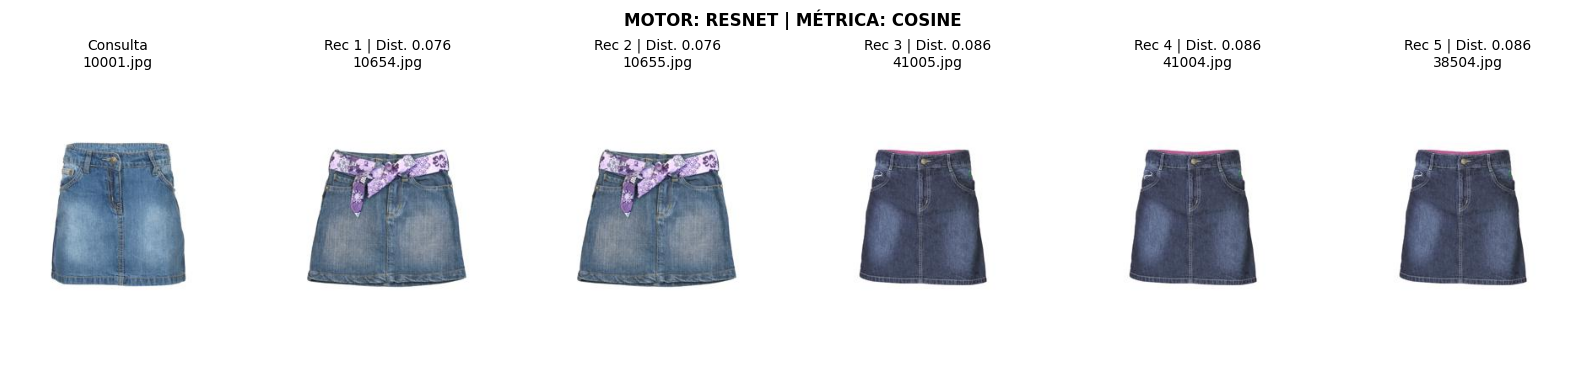

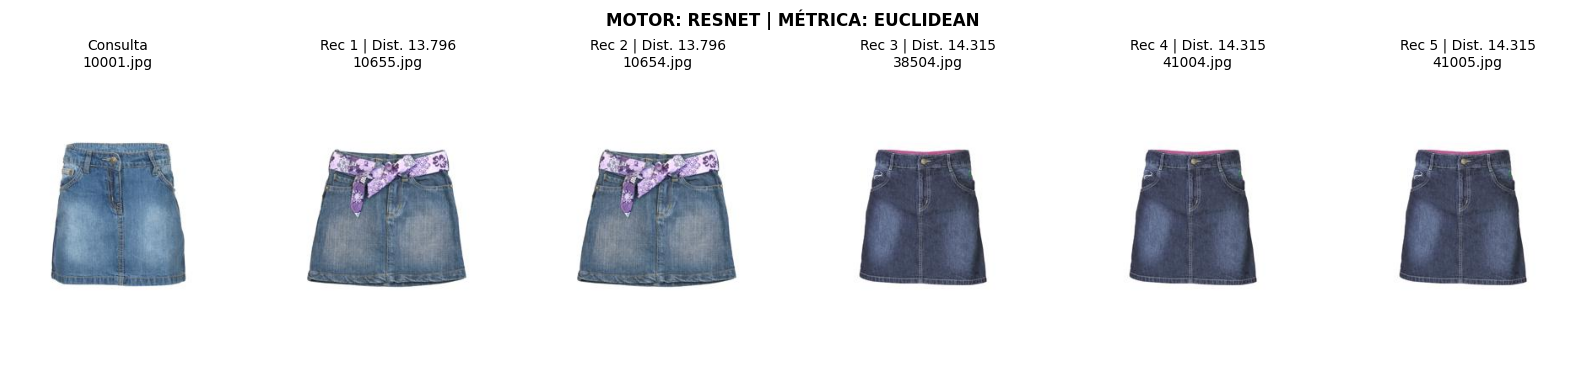

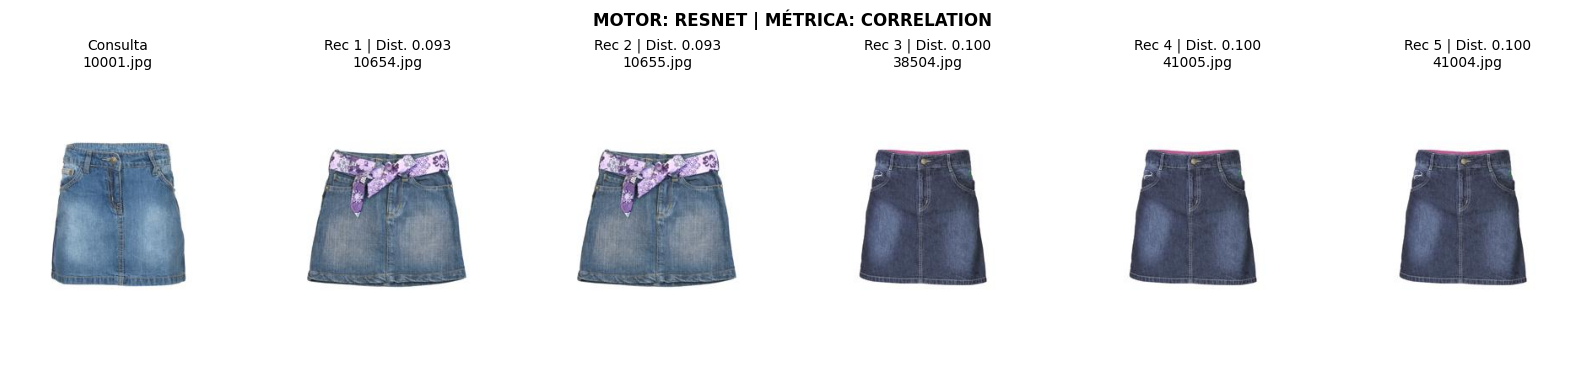

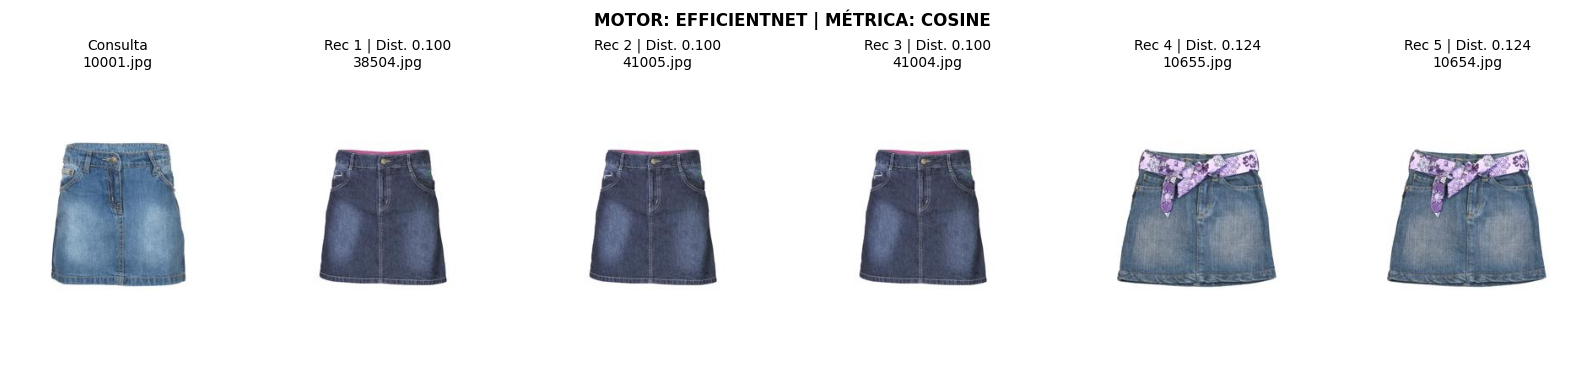

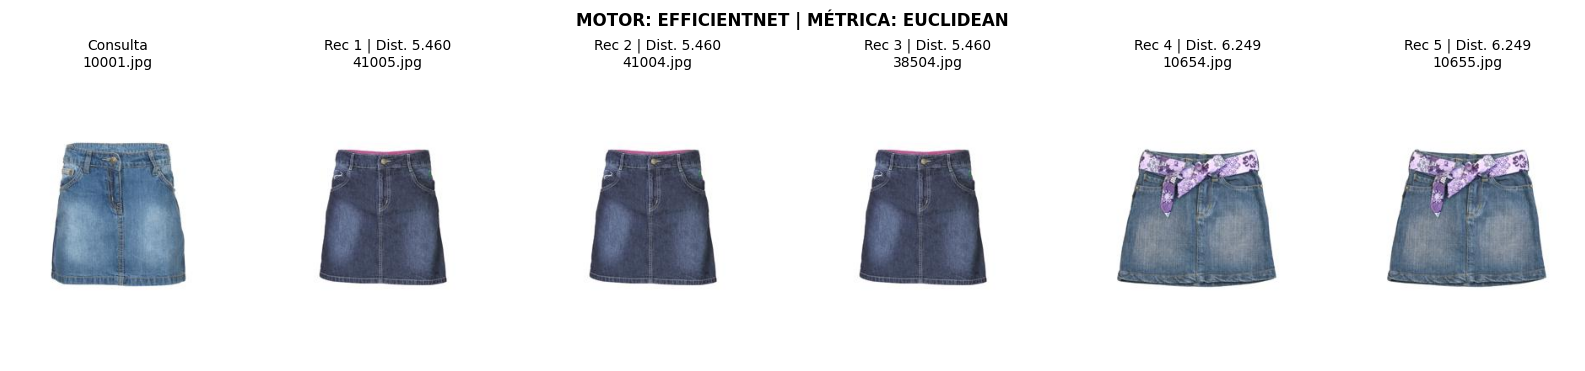

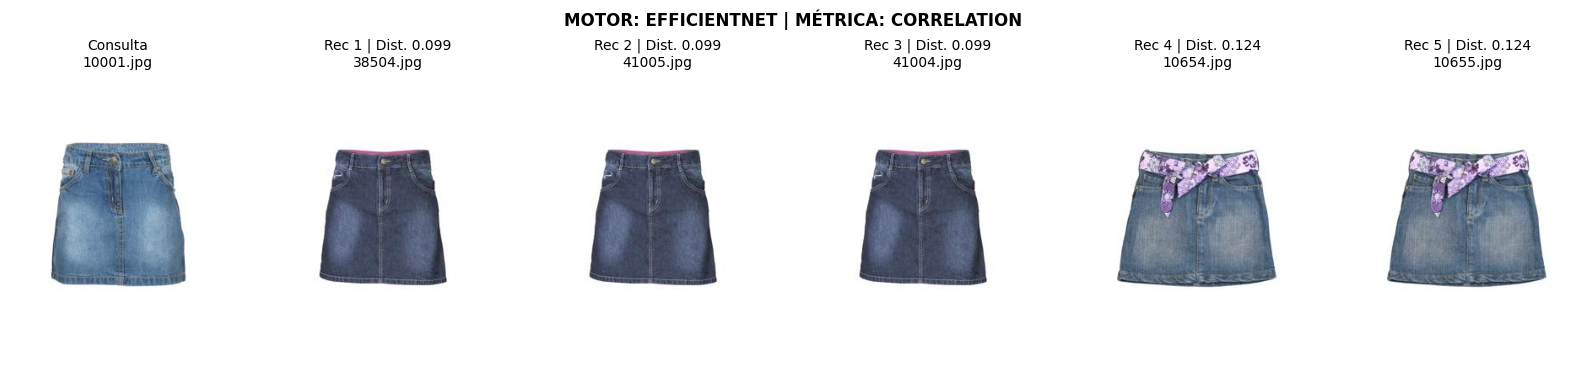

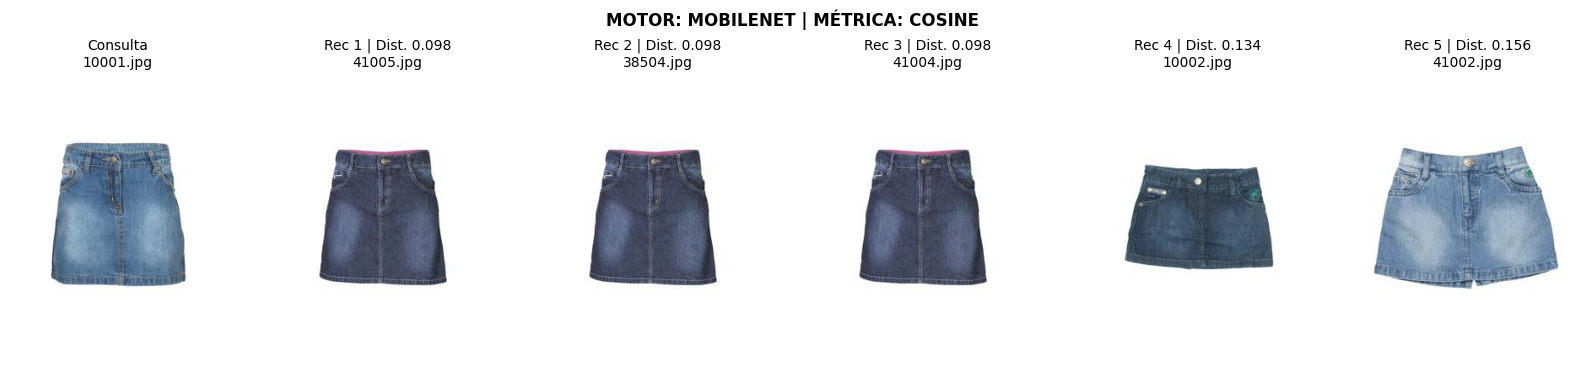

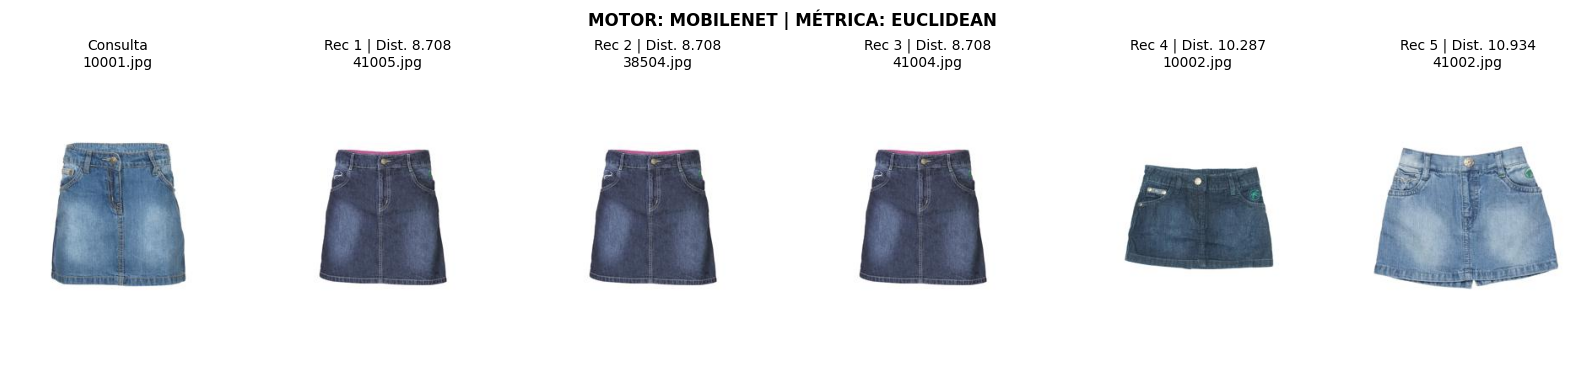

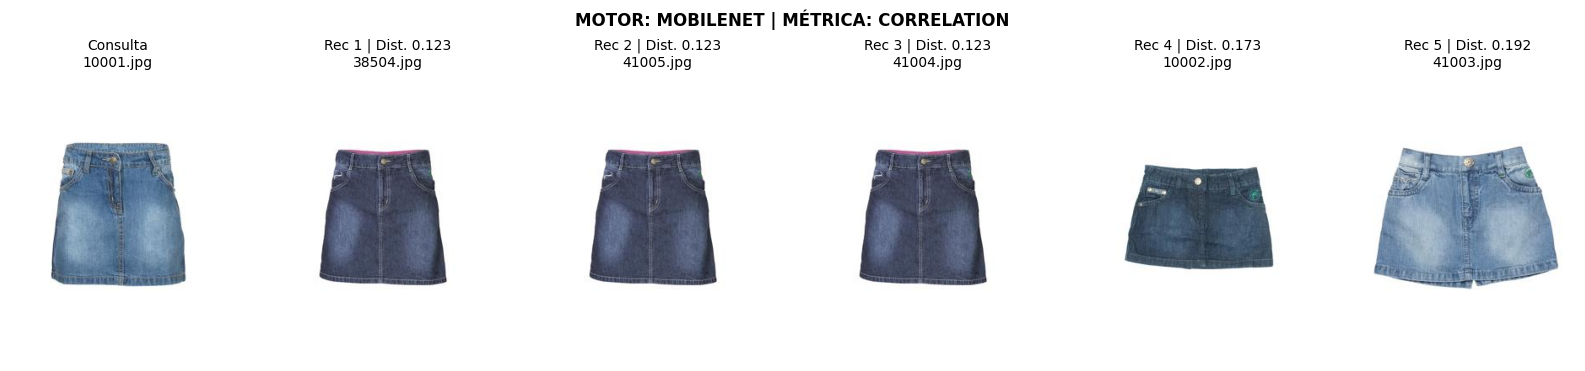

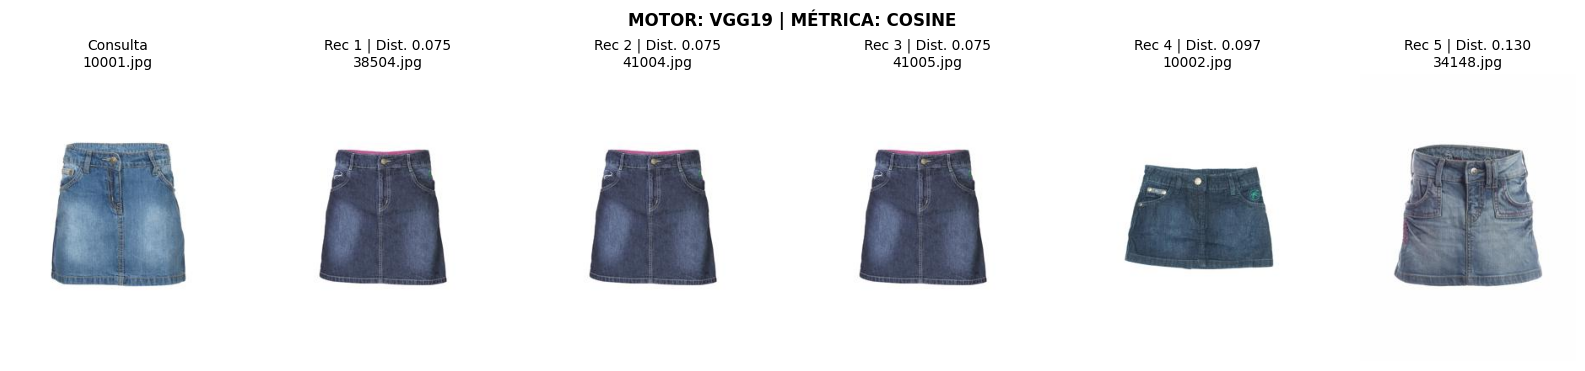

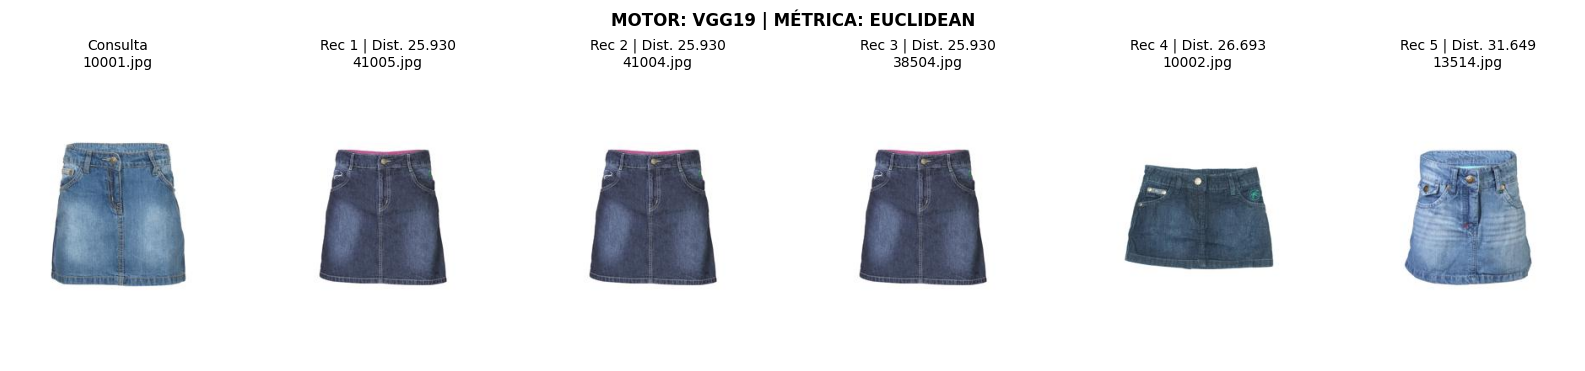

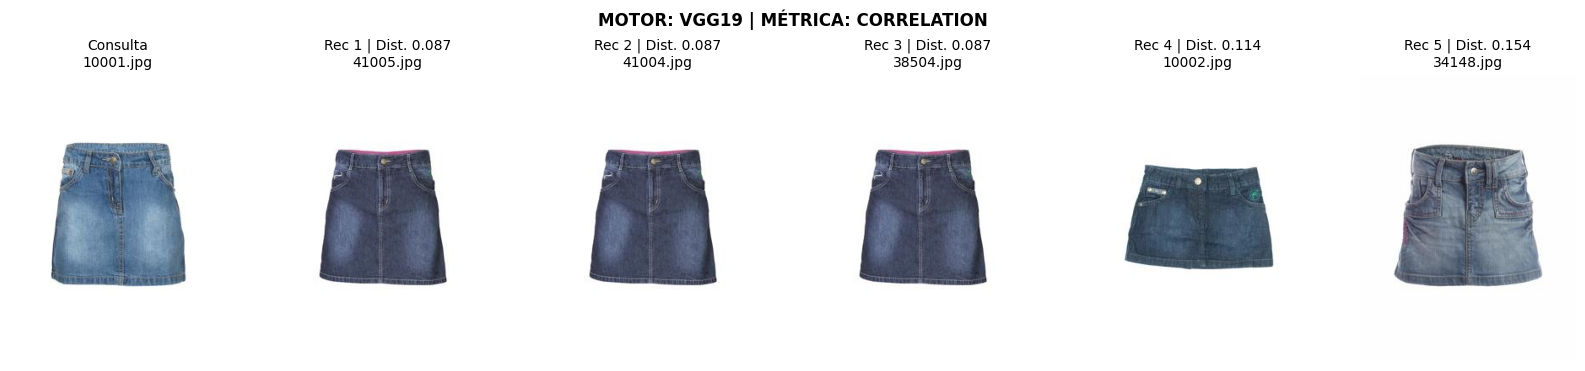

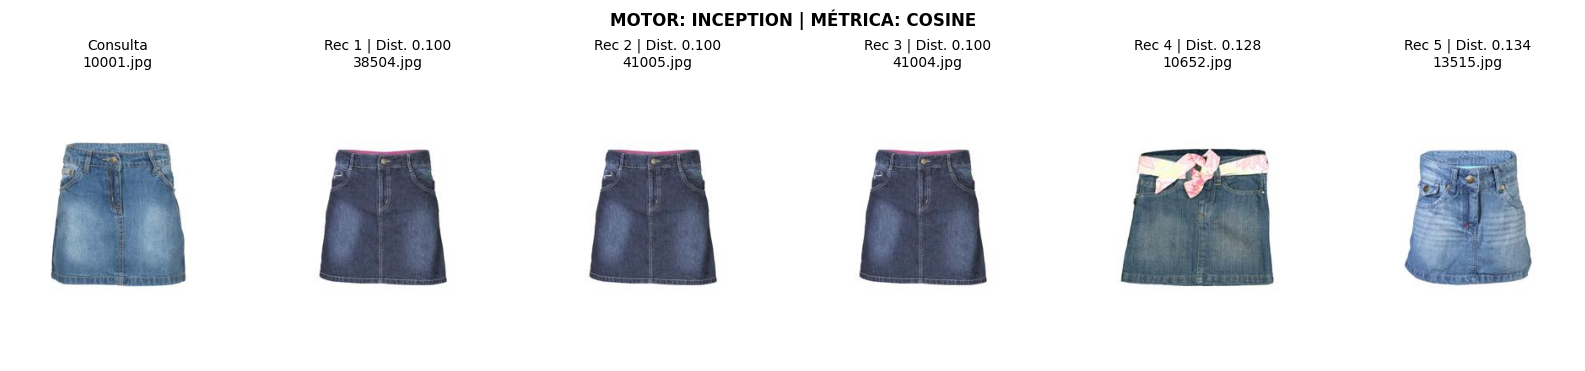

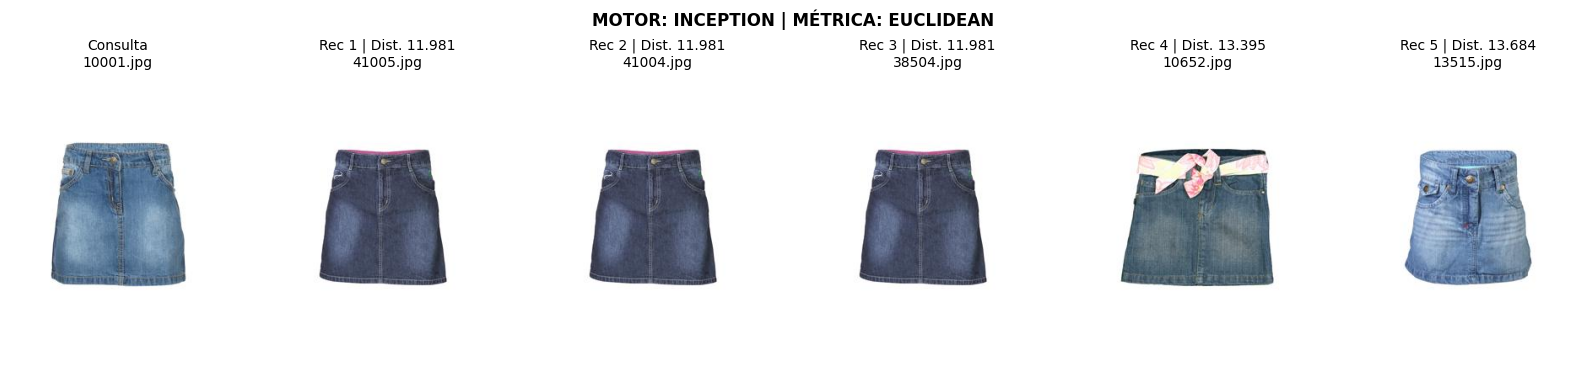

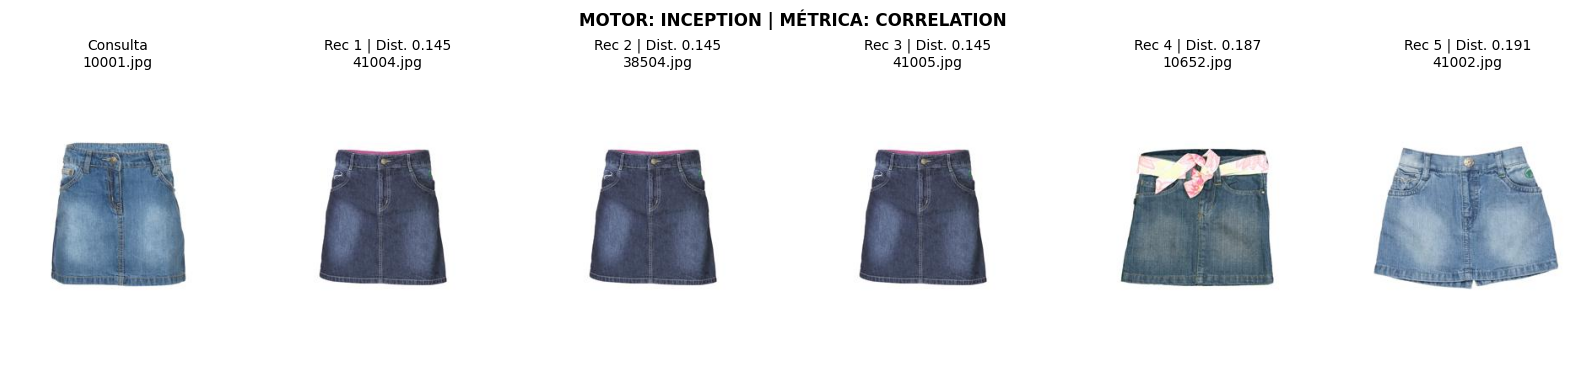

In [15]:
from tensorflow.keras.utils import load_img

def carregar_para_exibir(caminho):
    with load_img(caminho, color_mode='rgb') as imagem:
        return np.array(imagem)

def plotar_resultados(caminho_consulta, indices, distancias, titulo):
    if len(indices) != len(distancias):
        raise ValueError('Cada recomendação precisa ter uma distância correspondente.')

    itens = [(caminho_consulta, 'Consulta')]
    for posicao, (indice, distancia) in enumerate(zip(indices, distancias), start=1):
        itens.append((caminhos_tf[indice], f"Rec {posicao} | Dist. {distancia:.3f}"))

    fig, eixos = plt.subplots(
        1, len(itens), figsize=(2.7 * len(itens), 3.6), squeeze=False,
        layout='constrained',
    )
    for eixo, (caminho, rotulo) in zip(eixos[0], itens):
        eixo.imshow(carregar_para_exibir(caminho))
        eixo.set_title(f"{rotulo}\n{os.path.basename(caminho)}", fontsize=10)
        eixo.axis('off')

    fig.suptitle(titulo, fontsize=12, fontweight='bold')
    plt.show()
    plt.close(fig)

def visualizar_bateria_testes(dicionario_experimentos):
    for nome_exp, dados in dicionario_experimentos.items():
        modelo, metrica = nome_exp.split('_')
        plotar_resultados(
            dados['caminho_consulta'],
            dados['indices'],
            dados['scores'],
            f"MOTOR: {modelo.upper()} | MÉTRICA: {metrica.upper()}",
        )

visualizar_bateria_testes(experimentos)

#Teste Final

Nos testes visuais, a VGG19 usando a distância cosseno pareceu render melhores resultados, então seguiremos com ela para o próximo passo:

In [16]:
def recomendar(caminho_imagem_nova, k=5):
    # Aplica o mesmo carregamento e pré-processamento usados no catálogo.
    dados = tf.io.read_file(caminho_imagem_nova)
    imagem_rgb = tf.io.decode_image(dados, channels=3, expand_animations=False)
    imagem_redimensionada = tf.image.resize(imagem_rgb, (256, 256), method='bilinear')
    img_batch = converter_para_grayscale(imagem_redimensionada[tf.newaxis, ...])
    img_preparada = preprocess_vgg(img_batch)
    vetor_externo = model_extractor_vgg(img_preparada, training=False).numpy()

    knn = NearestNeighbors(n_neighbors=k, metric='cosine', algorithm='brute')
    knn.fit(VGG_embeddings)
    distancias, indices = knn.kneighbors(vetor_externo)

    return indices[0], distancias[0]

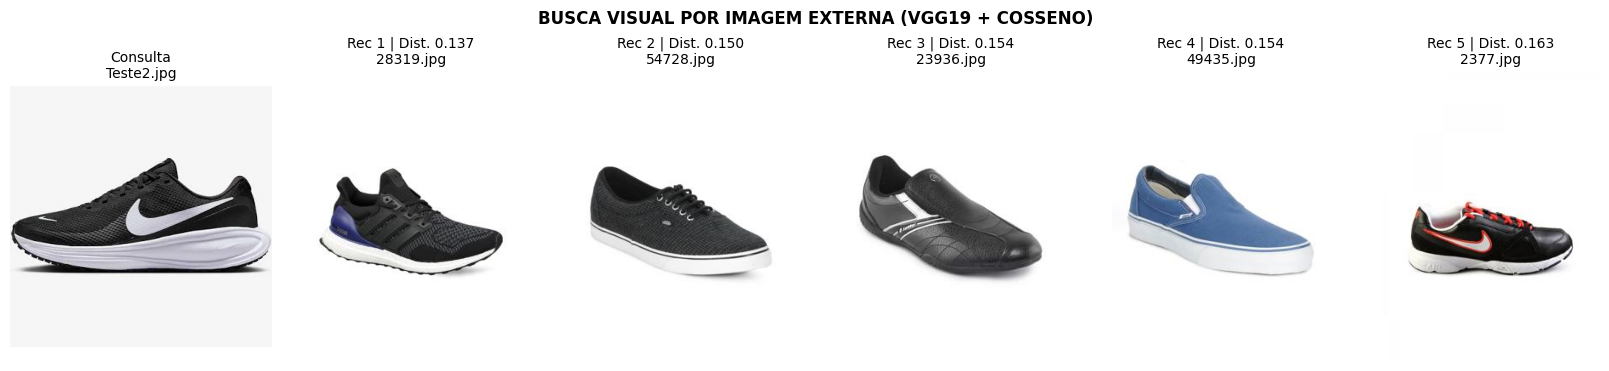

In [17]:
imagem_teste_externa = "Teste2.jpg"

if os.path.isfile(imagem_teste_externa):
    indices_encontrados, distancias_encontradas = recomendar(imagem_teste_externa, k=5)
    plotar_resultados(
        imagem_teste_externa,
        indices_encontrados,
        distancias_encontradas,
        "BUSCA VISUAL POR IMAGEM EXTERNA (VGG19 + COSSENO)",
    )
else:
    print(f"Envie '{imagem_teste_externa}' ao Colab ou ajuste o caminho da imagem.")

##Análise Final

Na consulta interna, a saia jeans `10001.jpg` retornou cinco saias jeans em cada uma das 15 combinações de modelo e distância. Alguns arquivos diferentes mostram peças visualmente quase idênticas, o que reduz a diversidade das recomendações.

Na consulta externa, a VGG19 com distância cosseno retornou cinco calçados para o tênis de `Teste2.jpg`, com distâncias entre 0,137 e 0,163. As recomendações foram coerentes com a categoria da consulta, com variação entre modelos esportivos e casuais.